# Restaurant Food Waste Prediction with a Stacking Ensemble (Restaurant Dataset, Improved Method)

This notebook is a modified copy of `restaurant_methodology.ipynb`. It uses the same models (Random Forest, XGBoost, SVR and a stacking ensemble) with the same settings. It adds descriptive statistics and evaluation metrics, reduces the training time of the stacking ensemble and explains its forecasts. Changed lines in the code are marked `# CHANGED:`.

Before any modelling, Section 1 checks the data quality: missing values, text formatting, category labels, invalid values, consistency between columns, outliers and duplicate records. Duplicate rows are removed before the split, so no event appears in both the training and the test set.

Changes from `restaurant_methodology.ipynb`:
1. Descriptive statistics and histograms of the numeric variables are added (Section 2).
2. MSE, RMSE and SMAPE are added to the metrics (Section 4).
3. The stacking meta-learner is tuned with `RidgeCV` instead of a grid search that retrains the whole stack (Section 6).
4. A new section compares the training time and accuracy of both tuning methods (Section 8).
5. A new section explains the forecasts of the stacking ensemble with SHAP and LIME (Section 9).
6. A baseline (the training mean) is added to the results as a reference point (Section 4).
7. A paired significance test checks whether the stacking ensemble's errors differ from the best single model's (Section 7).

The rows are separate events with no dates and no input contains the target, so the random split is kept and no input is removed. The predictions are not forecasts over time: each event's waste is predicted from details known when the event is planned, such as the number of guests, the quantity of food and the pricing.

| Section | Content |
|---|---|
| 0 | Setup: dataset location, libraries, configuration |
| 1 | Data loading, data quality checks and duplicate removal |
| 2 | Data analysis and descriptive statistics |
| 3 | One-hot encoding, train/test split, scaling |
| 4 | Evaluation metrics |
| 5 | Random Forest, XGBoost and SVR with grid search |
| 6 | Stacking 1: RF + XGBoost + SVR → Ridge |
| 7 | Results and plots |
| 8 | Stacking training time vs accuracy |
| 9 | Explainability: SHAP and LIME |

## 0. Setup
This section locates the dataset, imports the libraries and sets the configuration used throughout the notebook.

In [1]:
# Locate the dataset. On Google Colab the GitHub repository is cloned first;
# when run locally, the notebook already sits next to the dataset in the repository folder.
import os, sys
GITHUB_USER = "yklee7285"                     # GitHub account that hosts the public repository
REPO        = "food-demand-forecasting-fyp"
DATA_PATH   = "datasets/restaurant_dataset.csv"

if "google.colab" in sys.modules and not os.path.exists(DATA_PATH):
    if not os.path.isdir(REPO):
        !git clone -q https://github.com/{GITHUB_USER}/{REPO}.git
    %cd {REPO}

In [2]:
# Standard library; hide warnings
import time, random, warnings
warnings.filterwarnings("ignore")

# Data handling, plotting and statistical tests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# scikit-learn: splitting, tuning, scaling, models and metrics
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge, RidgeCV   # CHANGED: RidgeCV added for the stacking meta-learner
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score   # CHANGED: mean_squared_error added for MSE and RMSE
from xgboost import XGBRegressor
sns.set_style("whitegrid")

# ---------------- Configuration ----------------
RANDOM_STATE      = 42        # seed for the train/test split and the tree models
TEST_SIZE         = 0.20      # share of rows held out for testing
CV_FOLDS          = 5         # folds for grid-search cross-validation and stacking
SCORING           = "neg_mean_absolute_error"   # grid search keeps the parameters with the lowest MAE
SVR_TARGET_SD     = 9.63      # SVR learns the target rescaled to this standard deviation; predictions are converted back to the original units
RIDGE_GRID        = {"alpha": [0.01, 0.1, 1, 10, 100]}   # alpha values tested for the Ridge meta-learner
SHAP_ROWS         = 100       # CHANGED: new setting. Number of test rows explained with SHAP (chosen at random)
TARGET            = "Wastage Food Amount"               # column being forecast
UNIT              = "amount"                            # the dataset gives no unit for the waste amount

def set_seeds(seed=RANDOM_STATE):
    # Fix the Python and NumPy random generators so results are repeatable
    random.seed(seed); np.random.seed(seed)
set_seeds()

## 1. Data loading and data quality
This loads the dataset, checks its quality and removes duplicate rows before any modelling.

In [3]:
df = pd.read_csv(DATA_PATH)       # each row is a separate event; the rows have no dates, so the file order is kept
print("Rows:", len(df), "| Columns:", df.shape[1])
display(df.head())

Rows: 1782 | Columns: 11


,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Wastage Food Amount
0,Meat,310,Corporate,450,Refrigerated,Regular,All Seasons,Buffet,Urban,Low,25
1,Meat,400,Birthday,500,Room Temperature,Regular,Winter,Buffet,Suburban,High,40
2,Vegetables,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27
3,Meat,491,Birthday,497,Refrigerated,Regular,All Seasons,Finger Food,Rural,High,32
4,Meat,300,Corporate,400,Refrigerated,Regular,Winter,Finger Food,Urban,Moderate,25


### Data quality checks and preprocessing
The checks cover missing values, text formatting, category labels, invalid values, consistency between columns, outliers (1.5 x IQR rule), duplicate rows and how varied the values are. Findings and how they are handled:
- No missing values, padded text, inconsistent labels or invalid values, and the waste is never larger than the food prepared.
- The IQR rule flags some large events (many guests) and some high waste values. They stay within realistic ranges, so they are kept.
- Some rows are exact copies of other rows. With a random split, a copy can end up in the training set and another in the test set, so the model would be tested on events it has already seen. Duplicate rows are therefore removed before the split. This step does not use any values from the data, so it can be done before the split.
- Some events have identical inputs but different waste. These are kept as normal variation between events.
- The guest numbers and food quantities only take a few distinct value pairs, so most events share their pair with many others. This suggests the dataset was built from a small number of base records; it cannot be changed and is noted as a limitation.

In [4]:
CAT_RAW = df.select_dtypes(exclude="number").columns.tolist()
NUM_RAW = ["Number of Guests", "Quantity of Food", TARGET]

# Missing values, blank or padded text and category labels
print("Missing values (expect 0):", df.isna().sum().sum(),
      "| Text with leading or trailing spaces (expect 0):", int(sum((df[c] != df[c].str.strip()).sum() for c in CAT_RAW)))
for c in CAT_RAW:
    print(f"  {c}: {df[c].value_counts().to_dict()}")

# Invalid values and consistency between columns
print("Zero or negative guests, food or waste (expect 0):", int((df[NUM_RAW] <= 0).sum().sum()),
      "| Waste larger than the food prepared (expect 0):", (df[TARGET] > df["Quantity of Food"]).sum())
print(f"Waste as a share of the food prepared: {(df[TARGET] / df['Quantity of Food']).min():.1%} to {(df[TARGET] / df['Quantity of Food']).max():.1%}")

# Outliers by the 1.5 x IQR rule
q1, q3 = df[NUM_RAW].quantile(0.25), df[NUM_RAW].quantile(0.75)
print("Outliers (1.5 x IQR):", ((df[NUM_RAW] < q1 - 1.5 * (q3 - q1)) | (df[NUM_RAW] > q3 + 1.5 * (q3 - q1))).sum().to_dict(),
      "| ranges:", {c: (int(df[c].min()), int(df[c].max())) for c in NUM_RAW})

# Duplicates and repeated values
inputs = [c for c in df.columns if c != TARGET]
print("Duplicate rows:", df.duplicated().sum(), "| groups of identical rows:", df[df.duplicated(keep=False)].groupby(list(df.columns)).ngroups,
      "| most copies of one row:", df[df.duplicated(keep=False)].groupby(list(df.columns)).size().max())
print("Identical inputs with different waste:", int((df.groupby(inputs)[TARGET].nunique() > 1).sum()), "groups")
print("Distinct (guests, food quantity) pairs:", df[["Number of Guests", "Quantity of Food"]].drop_duplicates().shape[0],
      "| distinct waste values:", df[TARGET].nunique())

# Preprocessing: remove duplicate rows, so no event appears in both the training and the test set
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {n_before - len(df)} | rows left: {len(df)}")

Missing values (expect 0): 0 | Text with leading or trailing spaces (expect 0): 0
  Type of Food: {'Meat': 437, 'Baked Goods': 419, 'Dairy Products': 387, 'Fruits': 328, 'Vegetables': 211}
  Event Type: {'Corporate': 515, 'Social Gathering': 461, 'Wedding': 438, 'Birthday': 368}
  Storage Conditions: {'Room Temperature': 1157, 'Refrigerated': 625}
  Purchase History: {'Regular': 1576, 'Occasional': 206}
  Seasonality: {'Winter': 632, 'All Seasons': 623, 'Summer': 527}
  Preparation Method: {'Sit-down Dinner': 781, 'Finger Food': 702, 'Buffet': 299}
  Geographical Location: {'Suburban': 821, 'Urban': 564, 'Rural': 397}
  Pricing: {'High': 674, 'Moderate': 673, 'Low': 435}
Zero or negative guests, food or waste (expect 0): 0 | Waste larger than the food prepared (expect 0): 0
Waste as a share of the food prepared: 2.1% to 15.4%
Outliers (1.5 x IQR): {'Number of Guests': 35, 'Quantity of Food': 0, 'Wastage Food Amount': 10} | ranges: {'Number of Guests': (207, 491), 'Quantity of Food': (2

## 2. Data analysis
This summarises the numeric variables with descriptive statistics and histograms, then plots how waste varies with the main inputs.

### Descriptive statistics
Count, mean, standard deviation, range, skewness and kurtosis of each numeric variable, followed by their histograms. Skewness measures asymmetry (0 means symmetric) and kurtosis measures how heavy the tails are (0 is the same as a normal distribution).

,count,mean,std,min,25%,50%,75%,max,missing,skewness,kurtosis
Wastage Food Amount,1618.0,28.629,10.398,10.0,20.00,27.0,35.00,63.0,0,0.502,-0.261
Number of Guests,1618.0,318.381,67.947,207.0,267.75,302.0,362.75,491.0,0,0.436,-0.510
Quantity of Food,1618.0,412.225,64.714,280.0,350.00,400.0,480.00,500.0,0,-0.154,-1.096


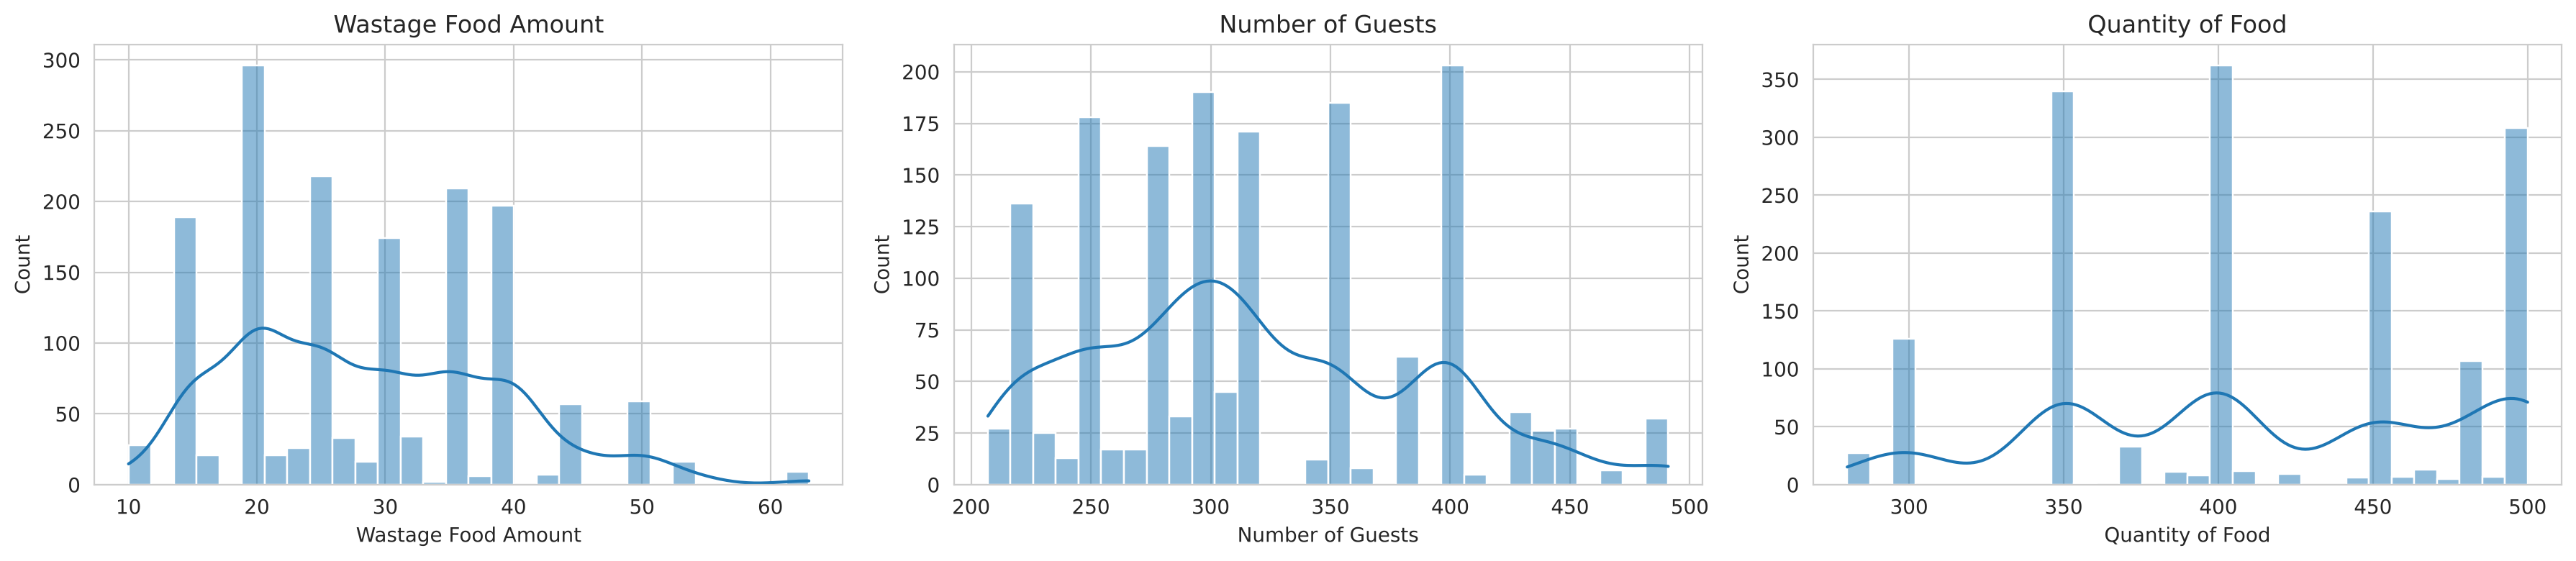

In [5]:
# CHANGED: new cell for descriptive statistics and histograms of the numeric variables
NUMERIC = [TARGET, "Number of Guests", "Quantity of Food"]
desc = df[NUMERIC].describe().T                      # count, mean, std, min, quartiles, max
desc["missing"]  = df[NUMERIC].isna().sum()
desc["skewness"] = df[NUMERIC].skew()
desc["kurtosis"] = df[NUMERIC].kurt()                # excess kurtosis, 0 for a normal distribution
display(desc.round(3))

# Histogram of each numeric variable
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for a, col in zip(axes.ravel(), NUMERIC):
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=a).set_title(col)
plt.tight_layout(); plt.show()

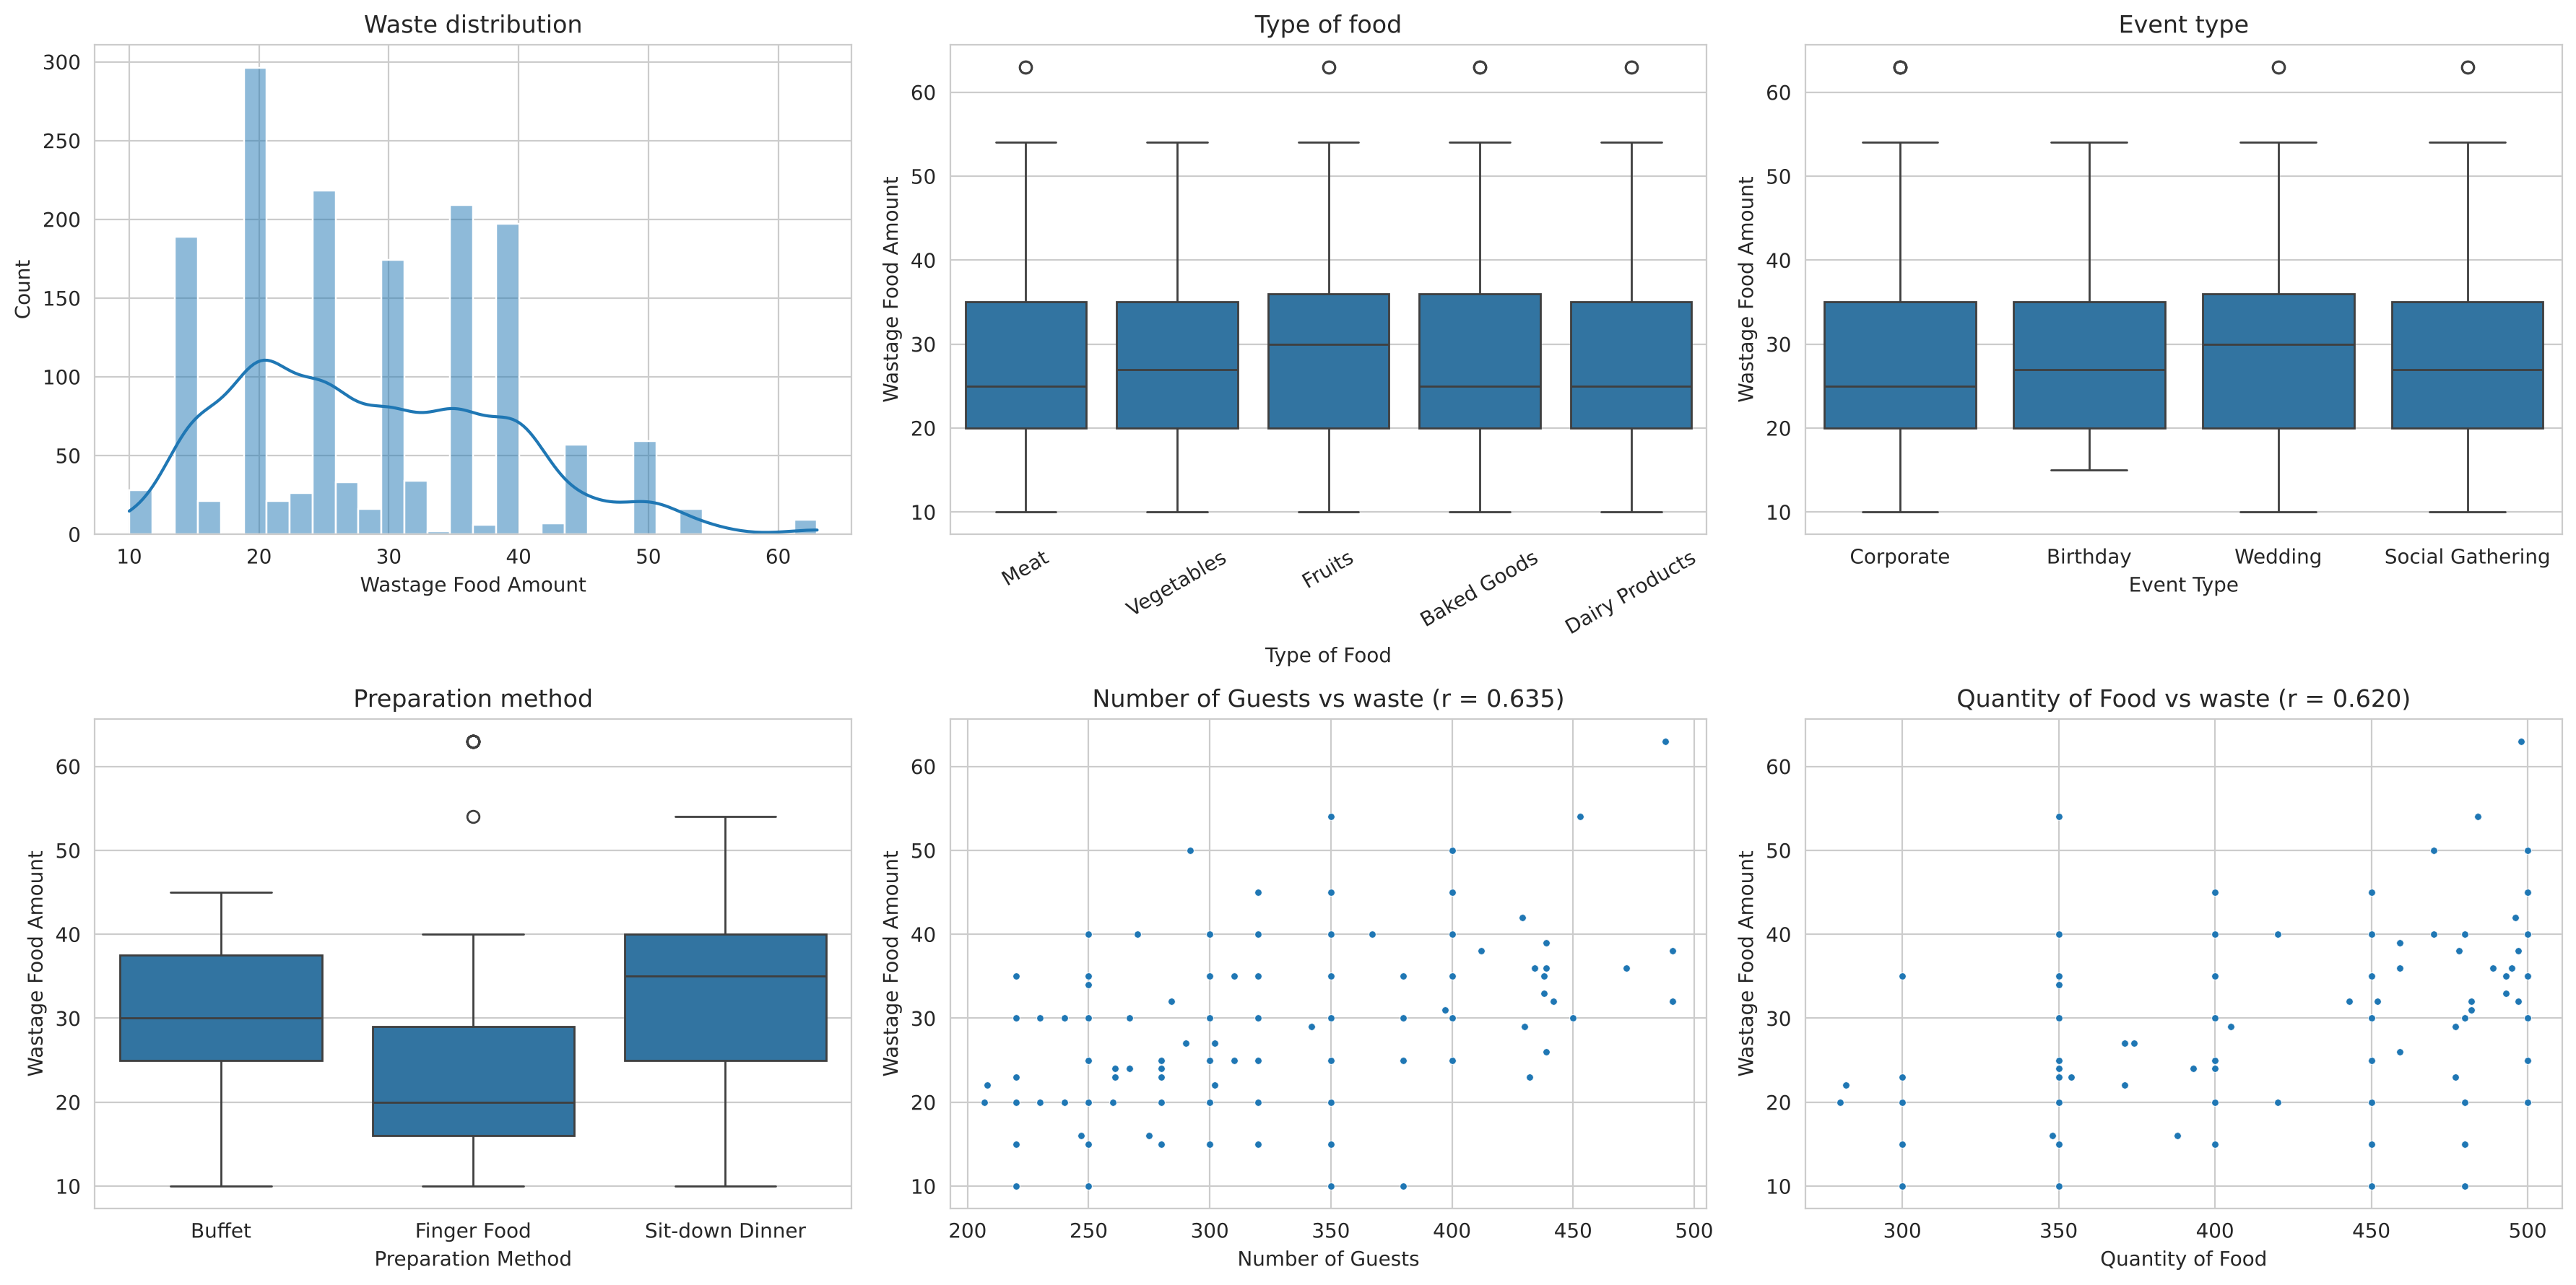

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
# Distribution of waste per event
sns.histplot(df[TARGET], bins=30, kde=True, ax=ax[0, 0]).set_title("Waste distribution")
# Waste by food type, event type and preparation method
sns.boxplot(data=df, x="Type of Food", y=TARGET, ax=ax[0, 1]).set_title("Type of food")
ax[0, 1].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="Event Type", y=TARGET, ax=ax[0, 2]).set_title("Event type")
sns.boxplot(data=df, x="Preparation Method", y=TARGET, ax=ax[1, 0]).set_title("Preparation method")
# Guests and quantity of food against waste, with their correlations in the titles
for a, col in [(ax[1, 1], "Number of Guests"), (ax[1, 2], "Quantity of Food")]:
    sns.scatterplot(data=df, x=col, y=TARGET, s=12, ax=a).set_title(f"{col} vs waste (r = {df[[col, TARGET]].corr().iloc[0, 1]:.3f})")
plt.tight_layout(); plt.show()

## 3. Encoding, split and scaling
1. Categorical inputs are one-hot encoded (one 0/1 column per category).
2. Rows are split at random into 80 % training and 20 % testing.
3. Inputs are scaled to 0–1 with a scaler fitted on the training rows only, so no test information enters training. The target stays in its original units.

In [7]:
CAT_COLS = ["Type of Food", "Event Type", "Storage Conditions", "Purchase History", "Seasonality",
            "Preparation Method", "Geographical Location", "Pricing"]
NUM_COLS = ["Number of Guests", "Quantity of Food"]

X = pd.get_dummies(df[CAT_COLS + NUM_COLS], columns=CAT_COLS, dtype=float)    # one-hot encode the categorical columns
y = df[TARGET].to_numpy(dtype=float)

# Random 80/20 split on row positions
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Fit the scaler on training predictors only, then apply it to every row
scaler = MinMaxScaler().fit(X.iloc[idx_tr])
X_all  = scaler.transform(X)
X_tr, X_te, y_tr, y_te = X_all[idx_tr], X_all[idx_te], y[idx_tr], y[idx_te]
print(f"{X.shape[1]} inputs | train {X_tr.shape} | test {X_te.shape}")
print(list(X.columns))

27 inputs | train (1294, 27) | test (324, 27)
['Number of Guests', 'Quantity of Food', 'Type of Food_Baked Goods', 'Type of Food_Dairy Products', 'Type of Food_Fruits', 'Type of Food_Meat', 'Type of Food_Vegetables', 'Event Type_Birthday', 'Event Type_Corporate', 'Event Type_Social Gathering', 'Event Type_Wedding', 'Storage Conditions_Refrigerated', 'Storage Conditions_Room Temperature', 'Purchase History_Occasional', 'Purchase History_Regular', 'Seasonality_All Seasons', 'Seasonality_Summer', 'Seasonality_Winter', 'Preparation Method_Buffet', 'Preparation Method_Finger Food', 'Preparation Method_Sit-down Dinner', 'Geographical Location_Rural', 'Geographical Location_Suburban', 'Geographical Location_Urban', 'Pricing_High', 'Pricing_Low', 'Pricing_Moderate']


## 4. Evaluation metrics
$MAE=\frac1n\sum|y-\hat y|$ · $MSE=\frac1n\sum(y-\hat y)^2$ · $RMSE=\sqrt{MSE}$ · $MAPE=\frac{100}{n}\sum|\frac{y-\hat y}{y}|$ · $SMAPE=\frac{100}{n}\sum\frac{2|y-\hat y|}{|y|+|\hat y|}$ · $Accuracy=100-MAPE$ · $R^2=1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$

`evaluate` turns one model's test predictions into a row of the results table. `results`, `preds` and `truth` collect every model's output for Section 7.

In [8]:
def evaluate(name, y_true, y_pred, secs):
    # One results-table row: error metrics (in target units / %), R2, training time and test-set size
    mape  = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    smape = np.mean(2 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred))) * 100   # CHANGED: SMAPE added
    mse   = mean_squared_error(y_true, y_pred)                                                # CHANGED: MSE added
    return {"Model": name, "MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse),                                                               # CHANGED: RMSE added
            "MAPE (%)": mape, "SMAPE (%)": smape,
            "Accuracy (%)": 100 - mape, "R2": r2_score(y_true, y_pred), "Training time (s)": secs,
            "Test rows": len(y_true)}
results, preds, truth = [], {}, {}      # metric rows, test predictions and matching actual values per model

### Baseline
A simple forecast is the reference point for every model: every test event is forecast with the mean waste of the training set (the rows have no time order, so there is no previous value to use). A model is only useful if it does clearly better than this.

In [9]:
# CHANGED: new cell. Baseline: every test event gets the mean waste of the training set
t0 = time.time()
preds["Baseline"], truth["Baseline"] = np.full(len(y_te), y_tr.mean()), y_te
results.append(evaluate("Baseline (training mean)", y_te, preds["Baseline"], time.time() - t0))

## 5. Individual models: Random Forest, XGBoost, SVR
Each model is tuned by 5-fold grid search on the training set (lowest MAE wins), refitted on all training rows, and evaluated on the test set. The training time covers both the search and the refit. SVR is wrapped so that it learns the target rescaled to a standard deviation of `SVR_TARGET_SD`; its predictions are converted back to the original units.

In [10]:
svr_k = y_tr.std() / SVR_TARGET_SD     # factor that rescales the training target to SVR_TARGET_SD

GRIDS = {   # each model with its candidate hyperparameter values
    "RF":      (RandomForestRegressor(random_state=RANDOM_STATE),
                {"n_estimators": [50, 100], "max_depth": [5, 10, 20, None], "min_samples_split": [2, 5]}),
    "XGBoost": (XGBRegressor(random_state=RANDOM_STATE, n_jobs=1),
                {"n_estimators": [50, 100], "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 5, 7]}),
    # SVR (default RBF kernel and gamma) learns the target divided by svr_k; predictions are multiplied back to the original units
    "SVR":     (TransformedTargetRegressor(SVR(), func=lambda v: v / svr_k, inverse_func=lambda v: v * svr_k),
                {"regressor__C": [0.1, 1], "regressor__epsilon": [0.1, 0.2]}),
}
best = {}   # tuned model per name, reused by the stacking ensembles
for name, (est, grid) in GRIDS.items():
    # Grid search with 5-fold CV, then refit of the best setting on all training rows (timed together)
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=CV_FOLDS, scoring=SCORING, n_jobs=-1).fit(X_tr, y_tr)
    secs = time.time() - t0
    best[name], preds[name], truth[name] = gs.best_estimator_, gs.predict(X_te), y_te
    results.append(evaluate(name, y_te, preds[name], secs))
    print(f"{name:8s} {gs.best_params_}  ({secs:.1f}s)")

RF       {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}  (11.2s)


XGBoost  {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 100}  (1.6s)


SVR      {'regressor__C': 1, 'regressor__epsilon': 0.2}  (0.9s)


## 6. Stacking 1: RF + XGBoost + SVR → Ridge
The tuned RF, XGBoost and SVR models are combined with scikit-learn's `StackingRegressor`:
1. 5-fold cross-validation produces an out-of-fold prediction from each base model for every training row.
2. A Ridge regression learns how to weight those predictions. It sees only the predictions, not the original inputs.
3. The base models are refitted on all training rows.

Ridge's regularisation strength (`alpha`) is chosen by `RidgeCV` from the same candidate values, using MAE and leave-one-out cross-validation on the out-of-fold predictions. Since `alpha` only affects the Ridge step, the base models do not need to be retrained to compare `alpha` values, so each base model is trained 6 times (5 folds and a final fit) instead of once for every `alpha` value and fold. Section 8 measures the time saved.

In [11]:
t0 = time.time()
# Stack of the tuned base models with a Ridge meta-learner trained on 5-fold out-of-fold predictions.
# CHANGED: alpha is chosen by RidgeCV inside the stack instead of by a GridSearchCV around the whole stack.
# Alpha only affects the Ridge step, but the grid search retrained every base model for each of the
# 5 alpha values and 5 folds. RidgeCV tests the same alpha values with MAE on the out-of-fold predictions
# the stack already has, so the base models are only trained once. The model and settings are the same.
s1 = StackingRegressor(estimators=[("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])],
                       final_estimator=RidgeCV(alphas=RIDGE_GRID["alpha"], scoring=SCORING),
                       cv=CV_FOLDS, passthrough=False, n_jobs=-1).fit(X_tr, y_tr)
secs = time.time() - t0
preds["Stacking 1"], truth["Stacking 1"] = s1.predict(X_te), y_te
results.append(evaluate("Stacking 1 (RF, XGBoost, SVR)", y_te, preds["Stacking 1"], secs))
print(f"Stacking 1: alpha = {s1.final_estimator_.alpha_} | Ridge weights [RF, XGB, SVR] = {np.round(s1.final_estimator_.coef_, 3)} ({secs:.1f}s)")   # CHANGED: alpha read from RidgeCV

Stacking 1: alpha = 0.01 | Ridge weights [RF, XGB, SVR] = [ 0.414  0.601 -0.017] (1.7s)


## 7. Results
These are the test-set metrics for the baseline and all four models, evaluated on the same test rows.

In [12]:
# Results table: one row per model
res = pd.DataFrame(results).set_index("Model")
display(res.round(3))

,MAE,MSE,RMSE,MAPE (%),SMAPE (%),Accuracy (%),R2,Training time (s),Test rows
Model,,,,,,,,,
Baseline (training mean),8.622,107.955,10.390,35.593,30.708,64.407,-0.002,0.000,324
RF,1.811,8.211,2.865,7.045,6.626,92.955,0.924,11.237,324
XGBoost,1.914,8.410,2.900,7.484,7.029,92.516,0.922,1.620,324
SVR,4.080,31.260,5.591,16.279,14.885,83.721,0.710,0.925,324
"Stacking 1 (RF, XGBoost, SVR)",1.828,8.078,2.842,7.150,6.713,92.850,0.925,1.692,324


### Significance of the differences
The stacking ensemble is compared with the best single model (lowest MAE). Both models in a comparison predict the same test rows, so their absolute errors are paired row by row. A Wilcoxon signed-rank test checks whether one model's errors are consistently smaller than the other's; a p-value below 0.05 means the difference is unlikely to be due to chance. The rows are separate events, so their errors are independent.

In [13]:
# CHANGED: new cell. Paired Wilcoxon signed-rank test on the absolute errors of each model on the same test rows
from scipy.stats import wilcoxon

single = [m for m in ["RF", "XGBoost", "SVR", "LSTM"] if m in preds]
best_single = min(single, key=lambda m: mean_absolute_error(truth[m], preds[m]))   # single model with the lowest MAE
abs_err = lambda m: np.abs(np.ravel(truth[m]) - np.ravel(preds[m]))                 # absolute error of a model on every test row

tests = []
for m1, m2 in [("Stacking 1", best_single), ("Stacking 2", best_single), ("Stacking 2", "Stacking 1")]:
    if m1 not in preds or m2 not in preds:
        continue
    assert np.array_equal(np.ravel(truth[m1]), np.ravel(truth[m2]))                 # both models predict the same rows
    e1, e2 = abs_err(m1), abs_err(m2)
    p_value = wilcoxon(e1, e2).pvalue
    tests.append({"Comparison": f"{m1} vs {m2}", "MAE difference": e1.mean() - e2.mean(),
                  "Rows where the first model is better (%)": np.mean(e1 < e2) * 100,
                  "p-value": p_value, "Significant at 5 %": "yes" if p_value < 0.05 else "no"})
display(pd.DataFrame(tests).set_index("Comparison").round(4))

,MAE difference,Rows where the first model is better (%),p-value,Significant at 5 %
Comparison,,,,
Stacking 1 vs RF,0.0164,43.8272,0.1624,no


### Actual vs predicted
Left: each test prediction plotted against the actual value (red line = perfect prediction). Right: actual and predicted values across the test samples.

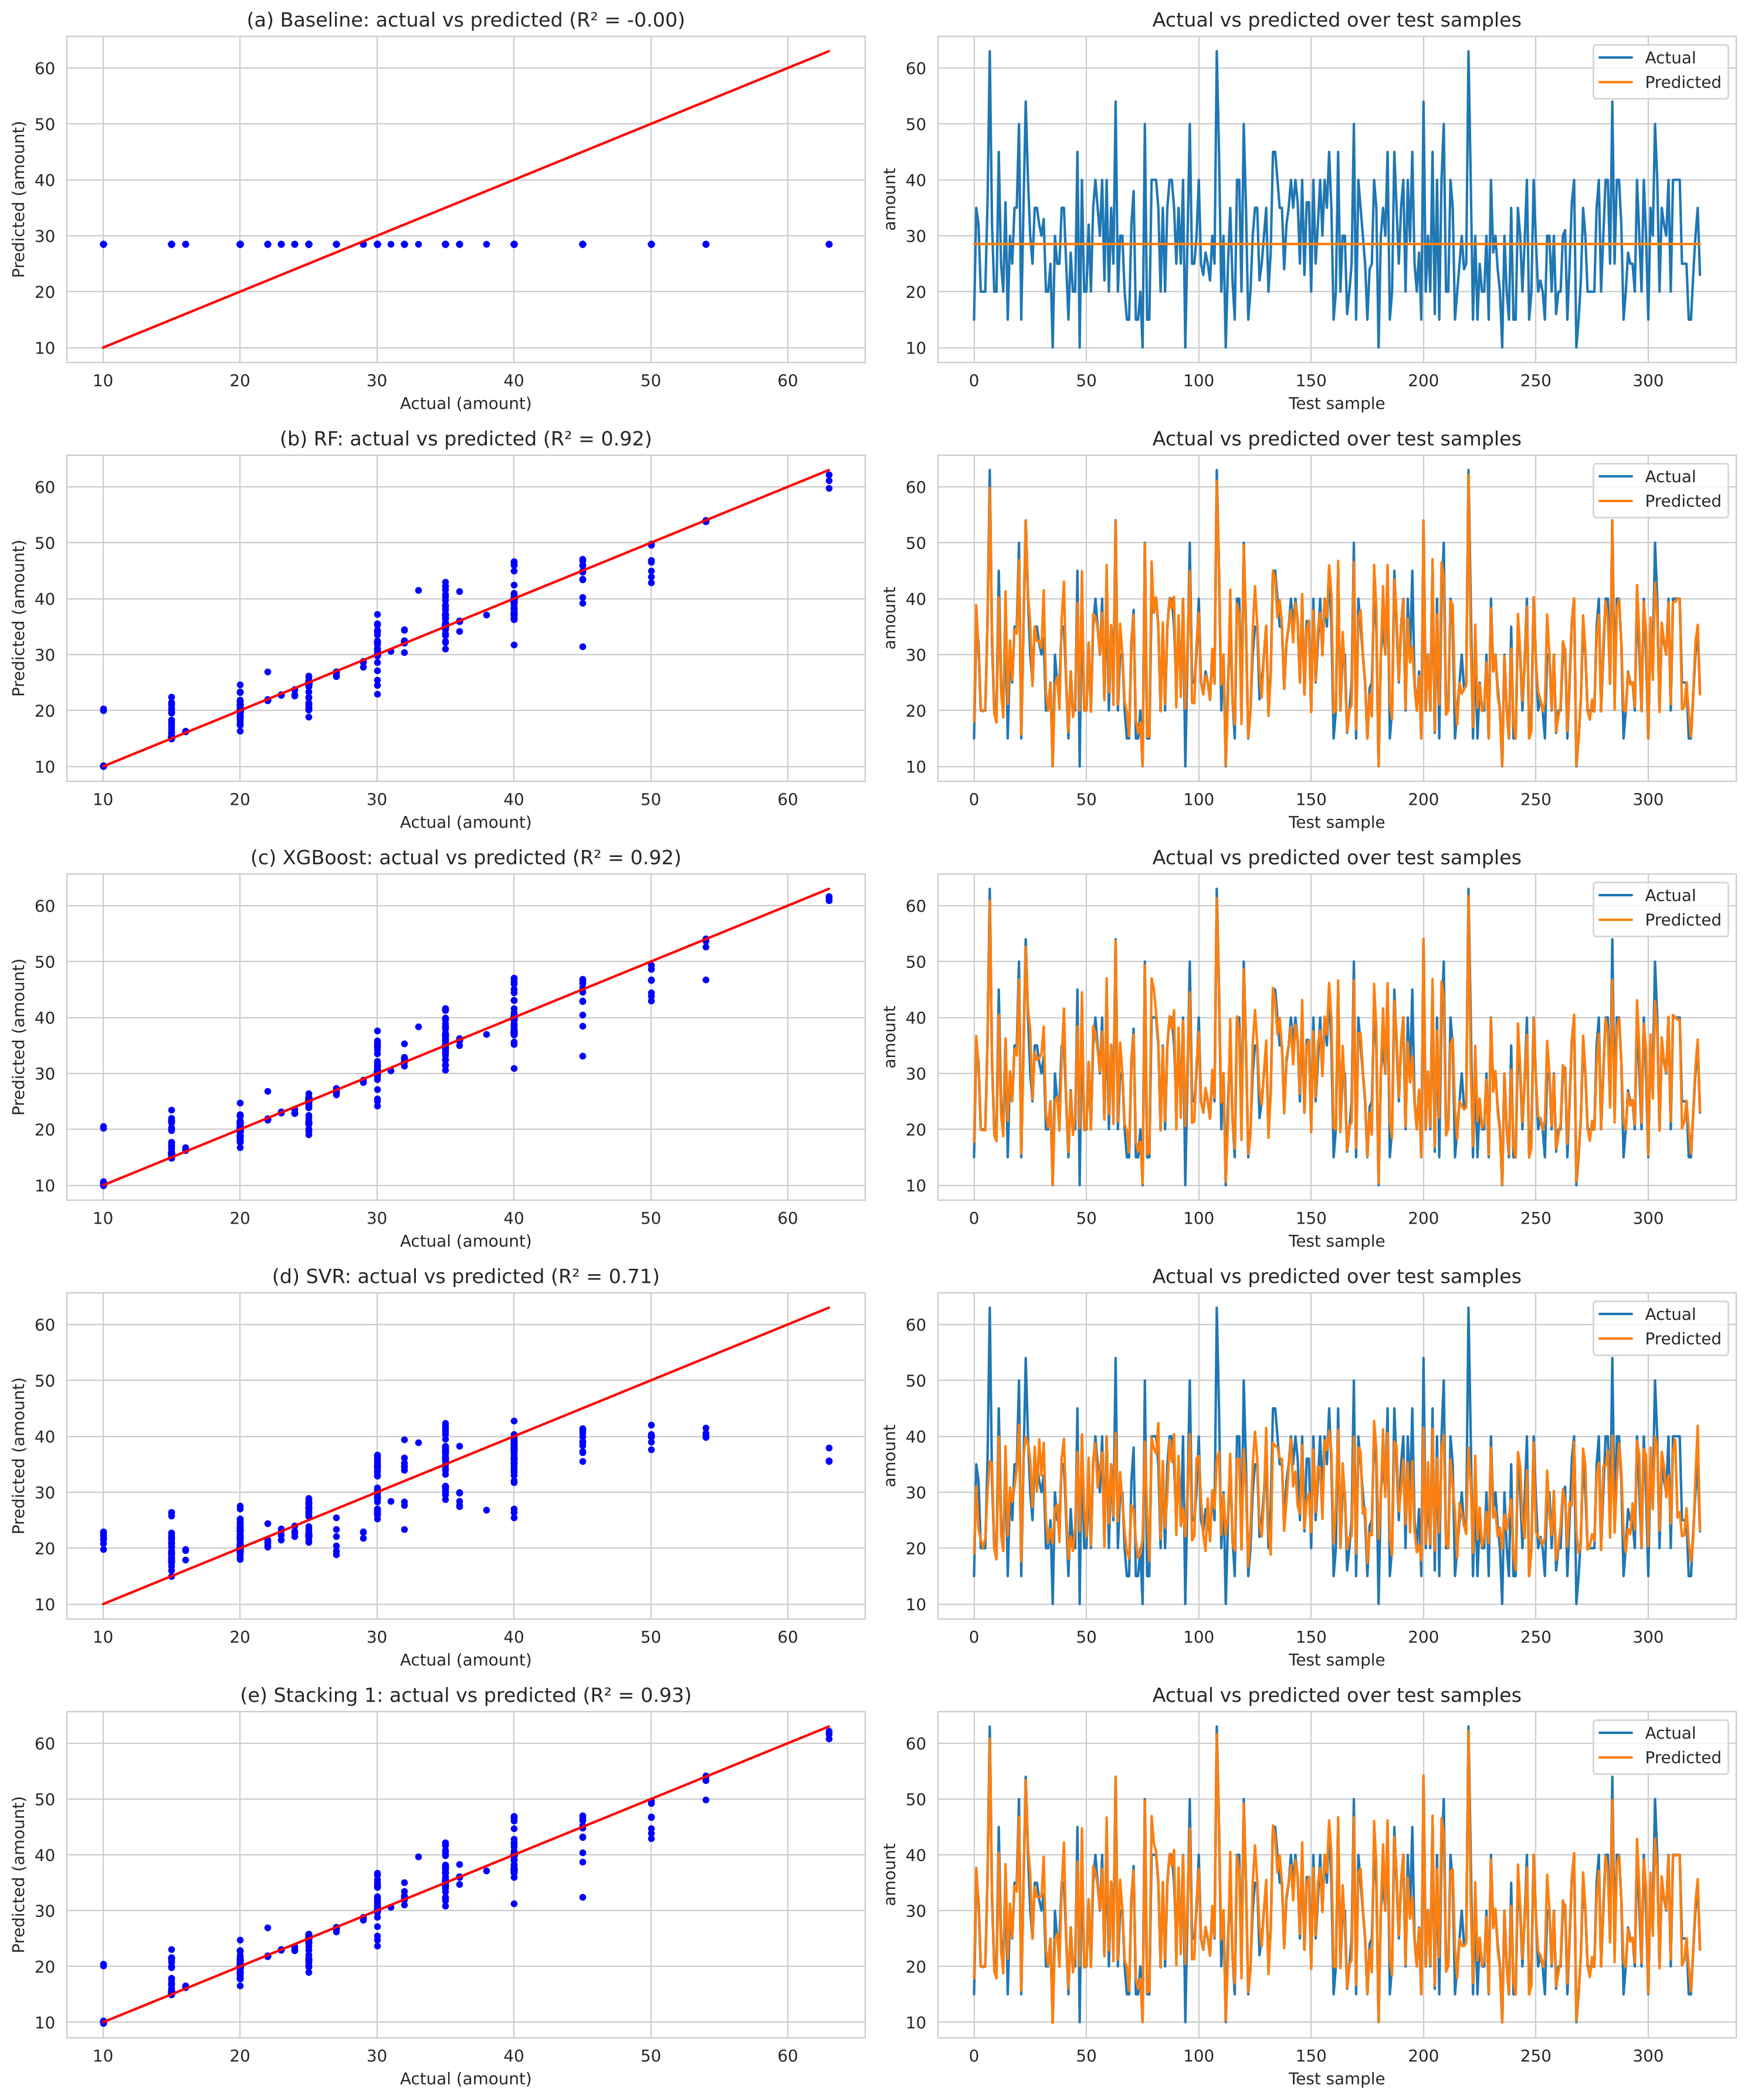

In [14]:
fig, axes = plt.subplots(len(preds), 2, figsize=(15, 3.6 * len(preds)))
for i, (name, p_) in enumerate(preds.items()):
    a = truth[name]; lims = [a.min(), a.max()]
    # Scatter of predicted vs actual with the identity line
    axes[i, 0].scatter(a, p_, s=10, c="blue"); axes[i, 0].plot(lims, lims, "r-")
    axes[i, 0].set(title=f"({'abcdefgh'[i]}) {name}: actual vs predicted (R² = {r2_score(a, p_):.2f})",   # CHANGED: more panel letters, because the baseline adds a row
                   xlabel=f"Actual ({UNIT})", ylabel=f"Predicted ({UNIT})")
    # Actual and predicted series over the test samples
    axes[i, 1].plot(a, label="Actual"); axes[i, 1].plot(p_, label="Predicted")
    axes[i, 1].set(title="Actual vs predicted over test samples", xlabel="Test sample", ylabel=UNIT); axes[i, 1].legend()
plt.tight_layout(); plt.show()

### Accuracy vs training time
R² (higher is better) and training time for each model, with the value labelled on each bar.

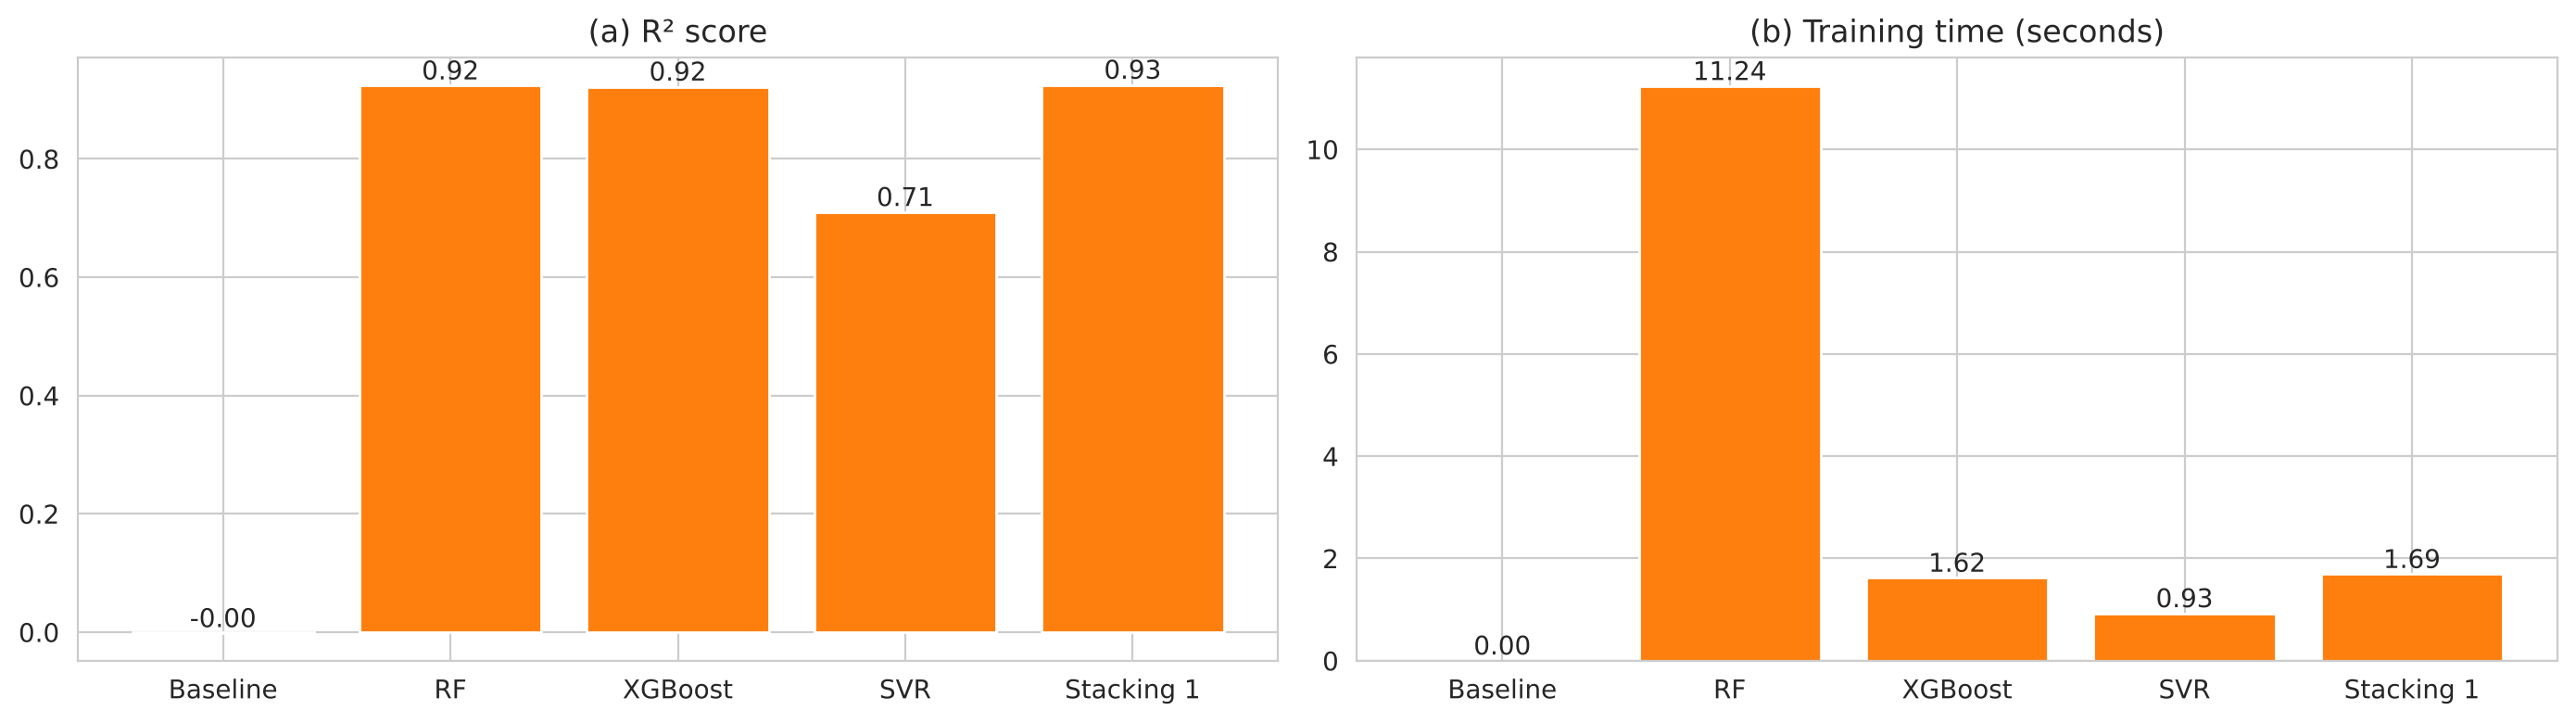

In [15]:
t = res.rename(index=lambda s: s.split(" (")[0])        # short model names for the x-axis
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, title in [(ax[0], "R2", "(a) R² score"), (ax[1], "Training time (s)", "(b) Training time (seconds)")]:
    a.bar(t.index, t[col], color="tab:orange"); a.set_title(title)
    for x, v in enumerate(t[col]): a.annotate(f"{v:.2f}", (x, v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 8. Stacking training time vs accuracy
This section is new. The stack is trained again with the original way of choosing alpha: a 5-fold GridSearchCV around the whole stack, which retrains all base models for every alpha value. The base models, settings and folds are the same as in Section 6, so the only difference is how alpha is chosen.

- Stacking time: time to train the stack, including choosing alpha.
- Total time: stacking time plus the grid search and training of the base models the stack reuses (their training times in the results table).

Why the new method is faster: alpha only changes the Ridge step, and Ridge only sees the base models' out-of-fold predictions. The original grid search retrained every base model for each alpha value and fold (25 times plus a final fit), which gives the same base-model predictions every time. RidgeCV compares the same alpha values with the same MAE scoring directly on those predictions, so the base models are only trained once per fold.

alpha    MAE   RMSE  \
Stack      Meta-learner tuning                                            
Stacking 1 Original: GridSearchCV around the stack  10.00  1.828  2.842   
           New: RidgeCV meta-learner                 0.01  1.828  2.842   

                                                    SMAPE (%)     R2  \
Stack      Meta-learner tuning                                         
Stacking 1 Original: GridSearchCV around the stack      6.713  0.925   
           New: RidgeCV meta-learner                    6.713  0.925   

                                                    Stacking time (s)  \
Stack      Meta-learner tuning                                          
Stacking 1 Original: GridSearchCV around the stack             40.890   
           New: RidgeCV meta-learner                            1.692   

                                                    Total time (s)  
Stack      Meta-learner tuning                                      
Stacking 1 Original: GridSearchCV around the stack          54.672  
           New: RidgeCV meta-learner                        15.474

Stacking 1: stacking time 40.9s -> 1.7s (24.2x faster), total 54.7s -> 15.5s, MAE 1.83 -> 1.83 (-0.00%)


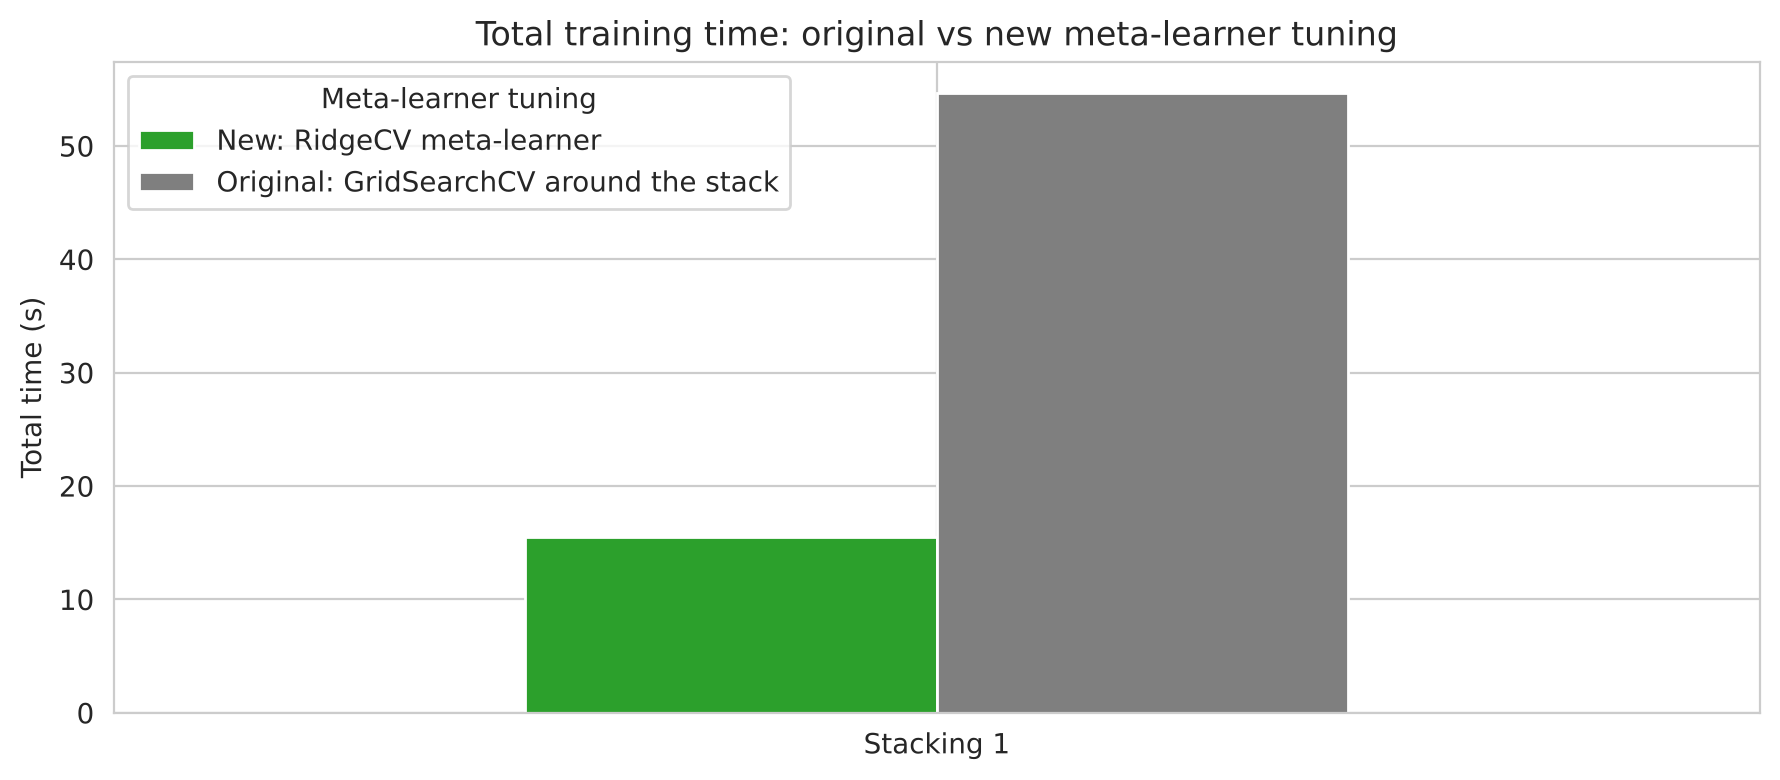

In [16]:
# CHANGED: new cell. Train the stack with the original alpha tuning and compare with Section 6
def original_tuning(estimators, X_fit):
    # Ridge meta-learner with alpha chosen by a GridSearchCV that retrains the whole stack for every alpha value
    stack = StackingRegressor(estimators=estimators, final_estimator=Ridge(), cv=CV_FOLDS, passthrough=False, n_jobs=-1)
    return GridSearchCV(stack, {"final_estimator__" + k: v for k, v in RIDGE_GRID.items()},
                        cv=CV_FOLDS, scoring=SCORING).fit(X_fit, y_tr)

base_secs = {r["Model"]: r["Training time (s)"] for r in results}                 # grid search and training time of each model
reuse = base_secs["RF"] + base_secs["XGBoost"] + base_secs["SVR"]                  # base-model time reused by the stack

t0 = time.time()
o1 = original_tuning([("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])], X_tr)
o1_secs = time.time() - t0

# One row per tuning method: chosen alpha, accuracy and time
rows = []
for tuning, pred, secs_, alpha in [
        ("Original: GridSearchCV around the stack", o1.predict(X_te), o1_secs, o1.best_params_["final_estimator__alpha"]),
        ("New: RidgeCV meta-learner", preds["Stacking 1"], base_secs["Stacking 1 (RF, XGBoost, SVR)"], s1.final_estimator_.alpha_)]:
    m = evaluate("Stacking 1", y_te, pred, secs_)
    rows.append({"Stack": "Stacking 1", "Meta-learner tuning": tuning, "alpha": alpha,
                 "MAE": m["MAE"], "RMSE": m["RMSE"], "SMAPE (%)": m["SMAPE (%)"], "R2": m["R2"],
                 "Stacking time (s)": secs_, "Total time (s)": secs_ + reuse})
ro1 = pd.DataFrame(rows).set_index(["Stack", "Meta-learner tuning"])
display(ro1.round(3))

# Time saved and change in MAE
old, new = ro1.loc["Stacking 1"].iloc[0], ro1.loc["Stacking 1"].iloc[1]
print(f"Stacking 1: stacking time {old['Stacking time (s)']:.1f}s -> {new['Stacking time (s)']:.1f}s "
      f"({old['Stacking time (s)'] / new['Stacking time (s)']:.1f}x faster), total {old['Total time (s)']:.1f}s -> {new['Total time (s)']:.1f}s, "
      f"MAE {old['MAE']:.2f} -> {new['MAE']:.2f} ({(new['MAE'] / old['MAE'] - 1) * 100:+.2f}%)")

# Total training time with both tuning methods
ax = ro1["Total time (s)"].unstack().plot(kind="bar", figsize=(9, 4), rot=0, color=["tab:green", "tab:gray"])
ax.set(ylabel="Total time (s)", title="Total training time: original vs new meta-learner tuning", xlabel="")
plt.tight_layout(); plt.show()

## 9. Explainability (SHAP and LIME)
This section is new. It explains the forecasts of the stacking ensemble. SHAP and LIME only use a model's predictions, so they explain the stack as a whole rather than its base models separately.

- SHAP splits each forecast into a contribution from every input. A positive contribution raises the forecast and a negative one lowers it. The contributions add up to the difference between that forecast and the average forecast over a reference sample of 100 training rows. SHAP is computed for `SHAP_ROWS` test rows chosen at random, to keep the run time manageable.
- The one-hot columns of each categorical input (for example the five `Type of Food` columns) are added together, so every original variable gets a single contribution.
- LIME fits a simple linear model to the stack's predictions around one row and reports the inputs with the largest effect. It is used to check the SHAP explanations of two example rows. LIME's conditions refer to the scaled inputs (0 to 1).

In [17]:
# CHANGED: new cell. Install SHAP and LIME if they are missing (e.g. on Colab), then import them
import importlib.util
if importlib.util.find_spec("shap") is None or importlib.util.find_spec("lime") is None:
    !pip install -q shap lime
import shap
from lime.lime_tabular import LimeTabularExplainer

In [18]:
# CHANGED: new cell. SHAP values of the stack for a random sample of test rows
ex = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(idx_te), min(SHAP_ROWS, len(idx_te)), replace=False))   # explained test rows
MODELS = {"Stacking 1": {"predict": s1.predict, "X_tr": X_tr, "X_te": X_te[ex], "names": list(X.columns)}}
bg = np.random.RandomState(RANDOM_STATE).choice(len(idx_tr), 100, replace=False)   # 100 reference rows

xai = {}
for name, m in MODELS.items():
    explainer = shap.PermutationExplainer(m["predict"], m["X_tr"][bg], feature_names=m["names"], seed=RANDOM_STATE)
    t0 = time.time()
    sv = explainer(m["X_te"])
    # Add the one-hot columns of each categorical input together, so each original variable has one contribution
    groups = {}
    for i, col in enumerate(m["names"]):
        groups.setdefault(next((c for c in CAT_COLS if col.startswith(c + "_")), col), []).append(i)
    var_shap = np.column_stack([sv.values[:, cols].sum(axis=1) for cols in groups.values()])
    xai[name] = {"sv": sv, "vars": list(groups), "shap": var_shap}
    # Check: base value + contributions should equal the stack's forecast for every explained row
    gap = np.abs(sv.base_values + var_shap.sum(axis=1) - m["predict"](m["X_te"])).max()
    print(f"{name}: SHAP values for {len(m['X_te'])} test rows in {time.time() - t0:.1f}s | largest gap to the forecast {gap:.3f} {UNIT}")

PermutationExplainer explainer:   5%|▌         | 5/100 [00:00<?, ?it/s]

PermutationExplainer explainer:   7%|▋         | 7/100 [00:13<01:48,  1.16s/it]

PermutationExplainer explainer:   8%|▊         | 8/100 [00:15<02:24,  1.57s/it]

PermutationExplainer explainer:   9%|▉         | 9/100 [00:17<02:46,  1.83s/it]

PermutationExplainer explainer:  10%|█         | 10/100 [00:19<02:52,  1.91s/it]

PermutationExplainer explainer:  11%|█         | 11/100 [00:21<02:53,  1.95s/it]

... (88 outputs left out)

PermutationExplainer explainer: 100%|██████████| 100/100 [03:57<00:00,  2.28s/it]

PermutationExplainer explainer: 101it [04:01,  2.77s/it]                         

PermutationExplainer explainer: 101it [04:01,  2.52s/it]

Stacking 1: SHAP values for 100 test rows in 241.7s | largest gap to the forecast 0.000 amount


### Global importance
Average size of each variable's contribution over the explained test rows (mean absolute SHAP value) and its share of the total. The beeswarm plot shows the individual input columns: each dot is one test row, its position is the contribution and its colour is the input value (red = high, or category present).

,Mean |SHAP| (amount),Share (%)
,Stacking 1,Stacking 1
Pricing,6.54,51.69
Number of Guests,2.24,17.71
Quantity of Food,1.86,14.72
Preparation Method,1.13,8.96
Geographical Location,0.34,2.72
Type of Food,0.17,1.35
Seasonality,0.13,1.04
Event Type,0.12,0.97
Storage Conditions,0.08,0.64


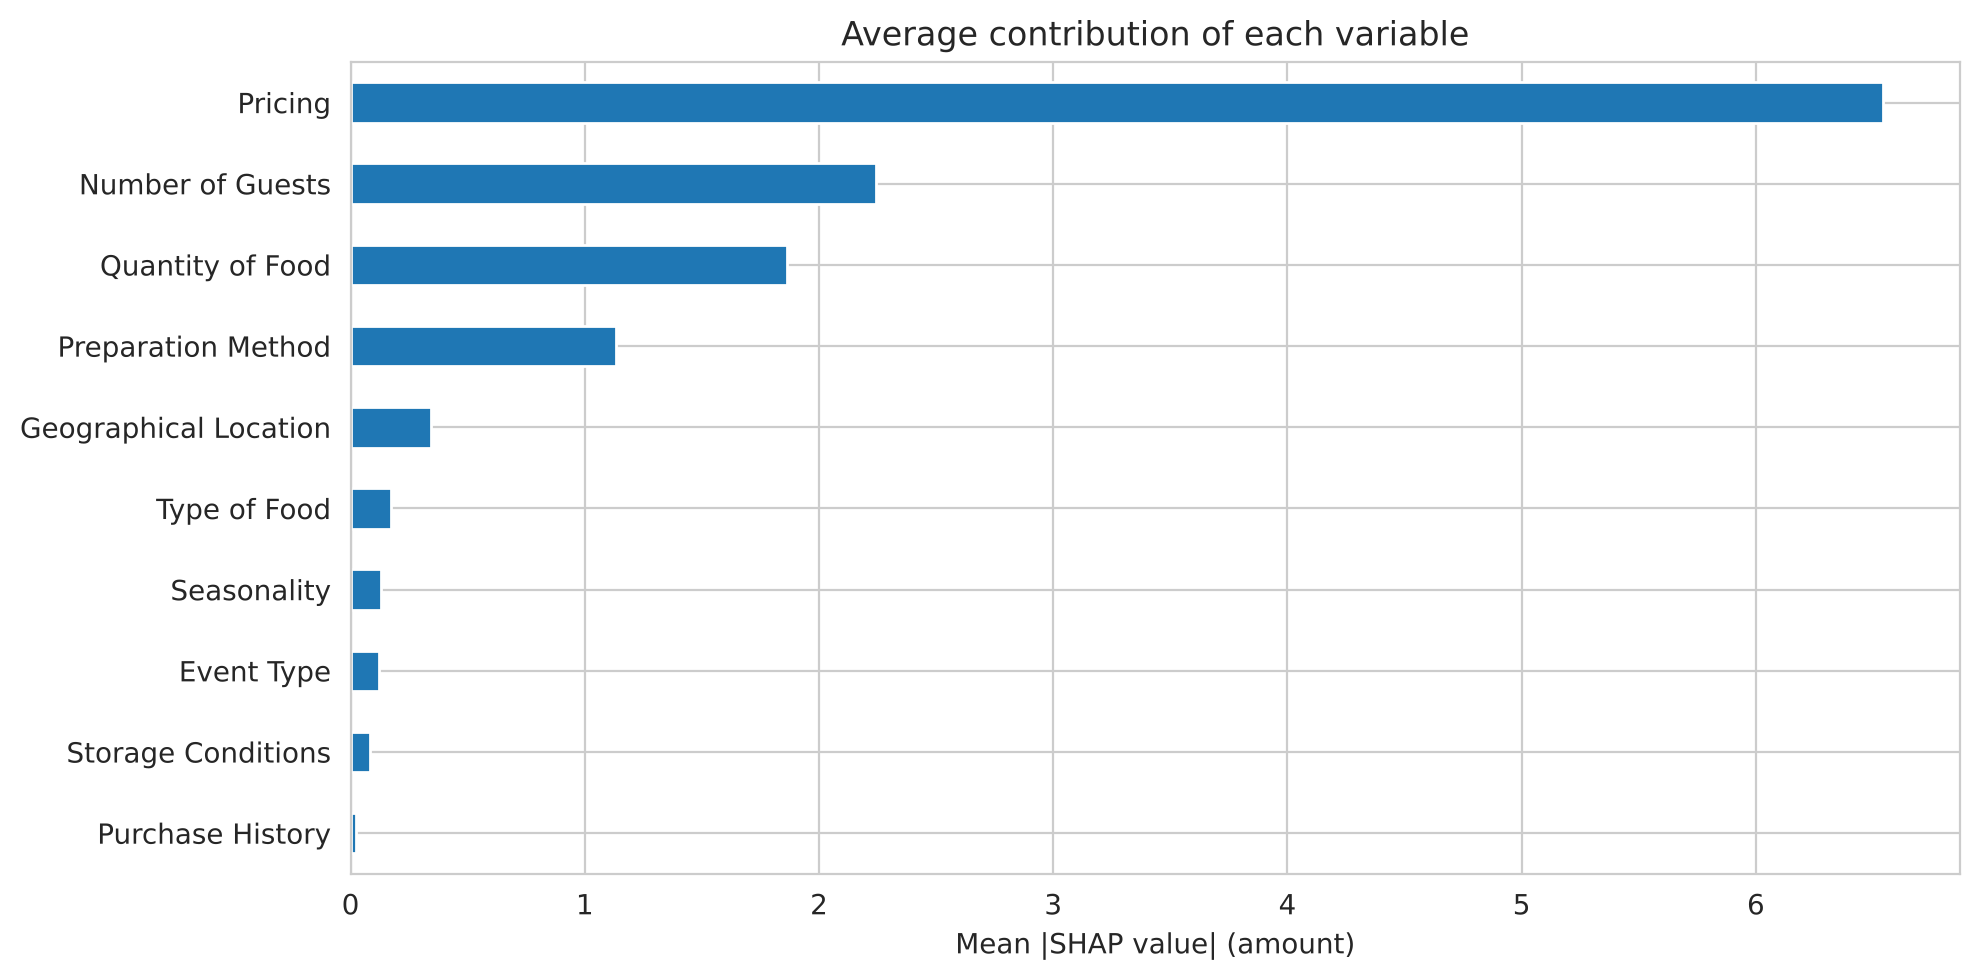

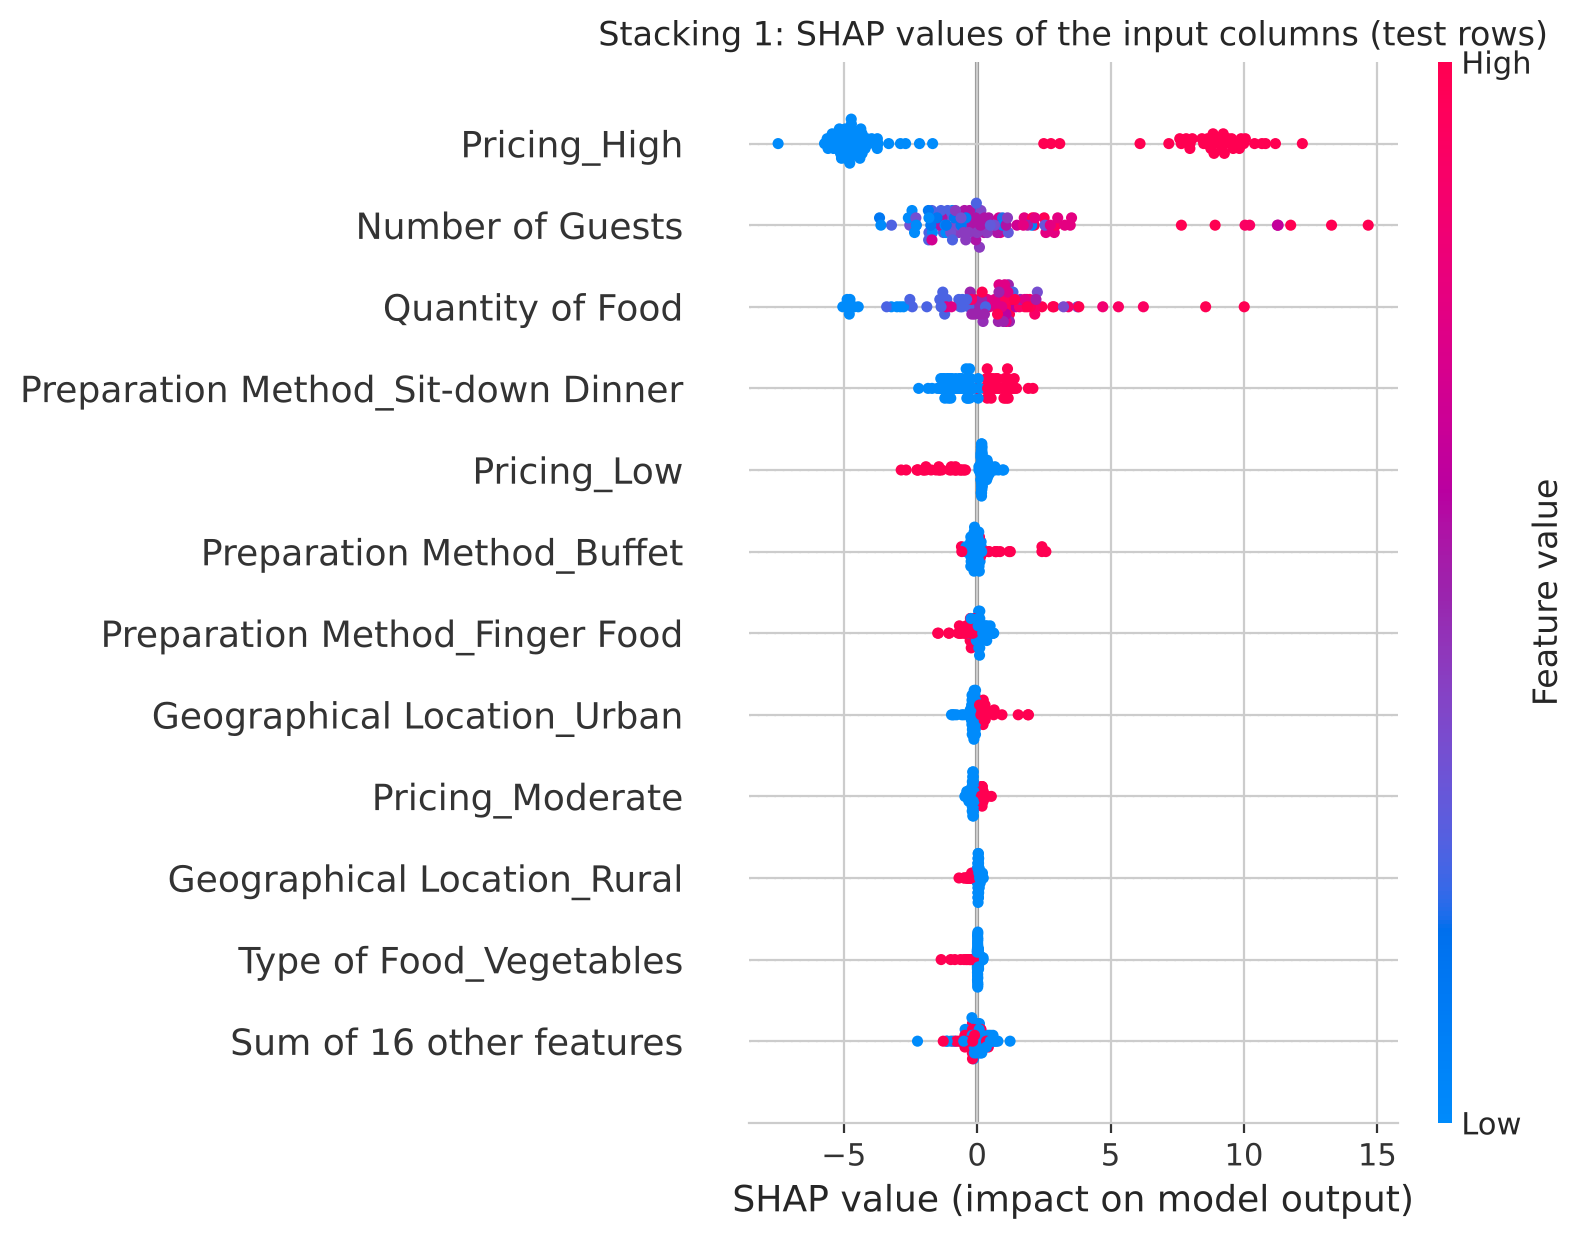

In [19]:
# CHANGED: new cell. Global importance of each original variable
imp = pd.concat({name: pd.Series(np.abs(r["shap"]).mean(axis=0), index=r["vars"]) for name, r in xai.items()}, axis=1)
imp = imp.sort_values("Stacking 1", ascending=False)
table = pd.concat({f"Mean |SHAP| ({UNIT})": imp, "Share (%)": imp / imp.sum() * 100}, axis=1)
display(table.round(2))

ax = imp.iloc[::-1].plot(kind="barh", figsize=(10, 5), color=["tab:blue"], legend=False)
ax.set(xlabel=f"Mean |SHAP value| ({UNIT})", title="Average contribution of each variable")
plt.tight_layout(); plt.show()

for name, r in xai.items():
    shap.plots.beeswarm(r["sv"], max_display=12, show=False)
    plt.title(f"{name}: SHAP values of the input columns (test rows)"); plt.tight_layout(); plt.show()

### Local explanations of two test rows
Two example rows are explained: the explained test rows with the highest and the lowest forecast. The waterfall plots start from the average forecast and add each variable's contribution to reach that row's forecast. The LIME tables list the conditions with the largest effect on the same forecasts, and the last line compares the three most important variables from both methods.

Highest forecast: Baked Goods, Wedding, 488 guests, 498 food | actual 63


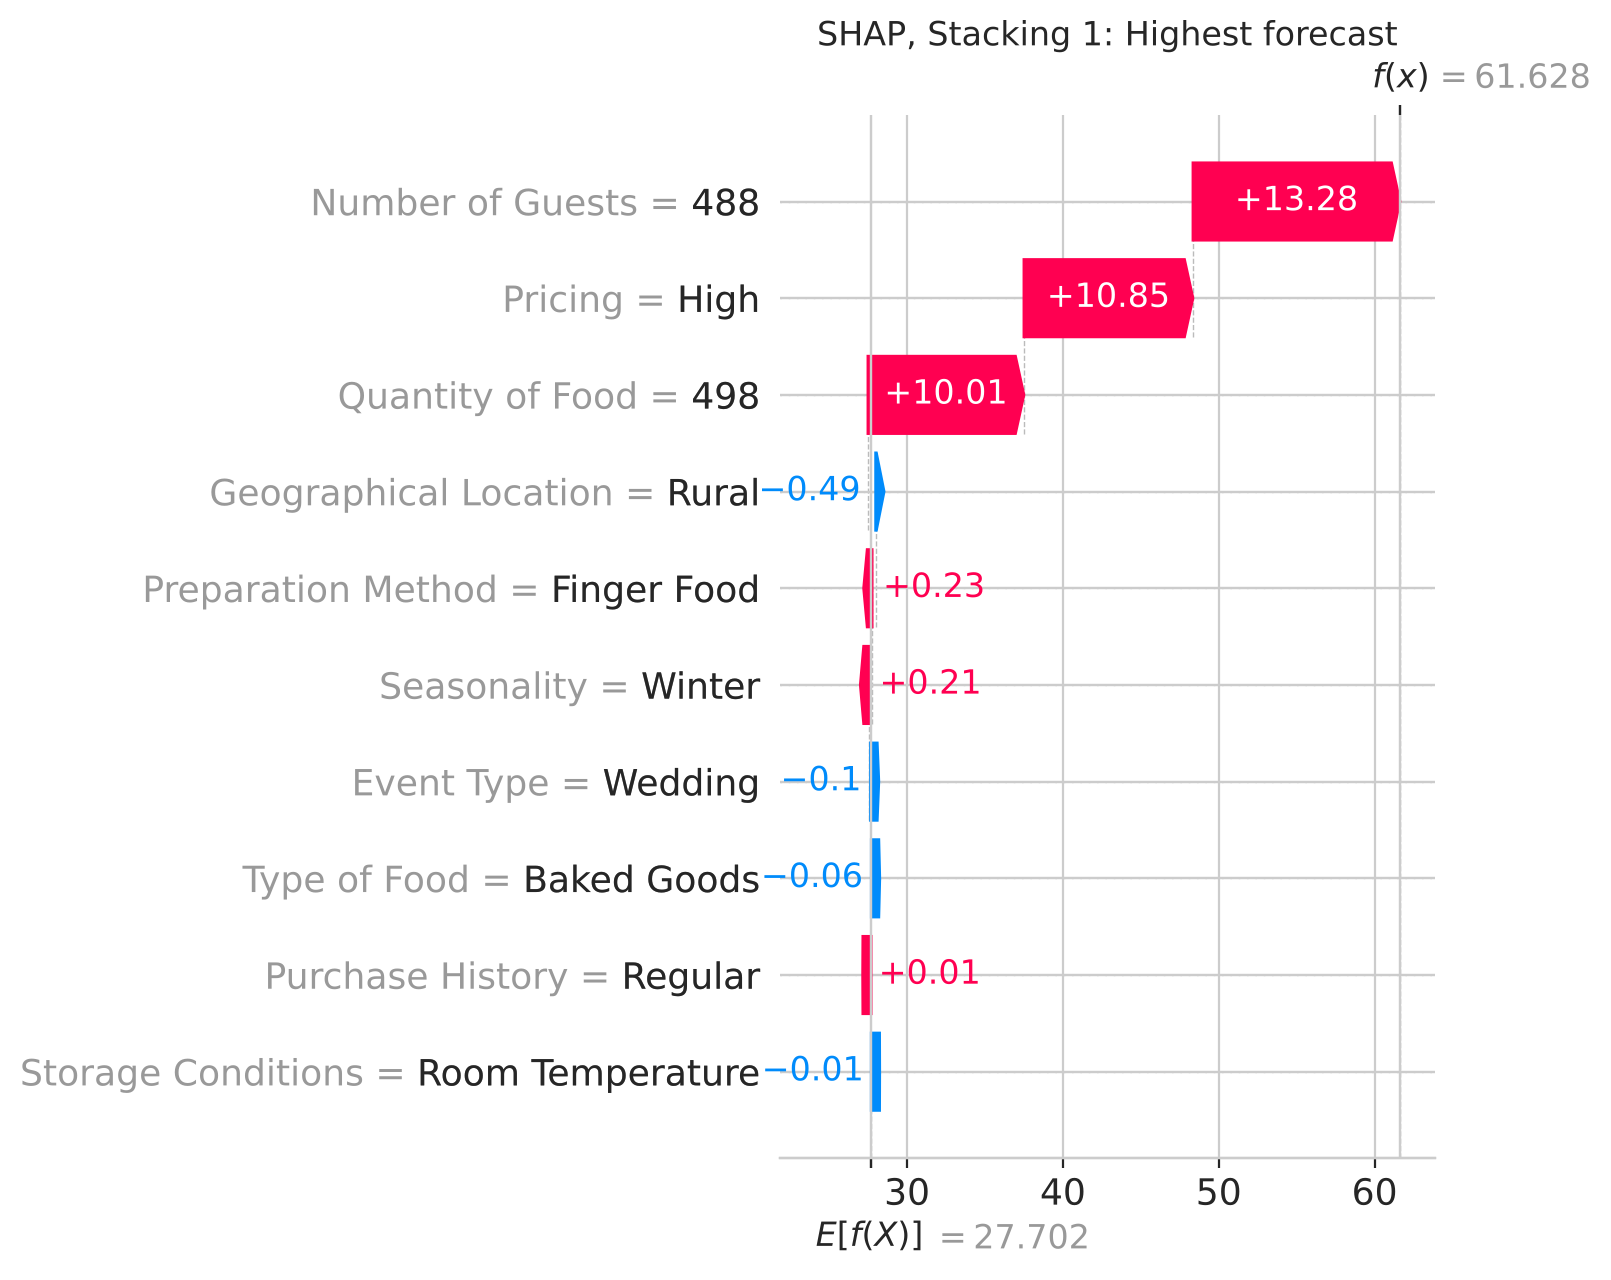

LIME, Stacking 1: Highest forecast | forecast 61.6


,LIME condition (scaled inputs),Effect
0,0.00 < Pricing_High <= 1.00,12.6
1,Number of Guests > 0.56,5.8
2,Quantity of Food > 0.91,2.1
3,Preparation Method_Sit-down Dinner <= 0.00,-1.3
4,Pricing_Low <= 0.00,1.2
5,Preparation Method_Buffet <= 0.00,-1.1
6,Geographical Location_Urban <= 0.00,-0.6
7,Type of Food_Vegetables <= 0.00,0.5


Top 3 variables, Stacking 1 - SHAP: ['Number of Guests', 'Pricing', 'Quantity of Food'] | LIME: ['Pricing', 'Number of Guests', 'Quantity of Food']

Lowest forecast: Meat, Corporate, 220 guests, 300 food | actual 10


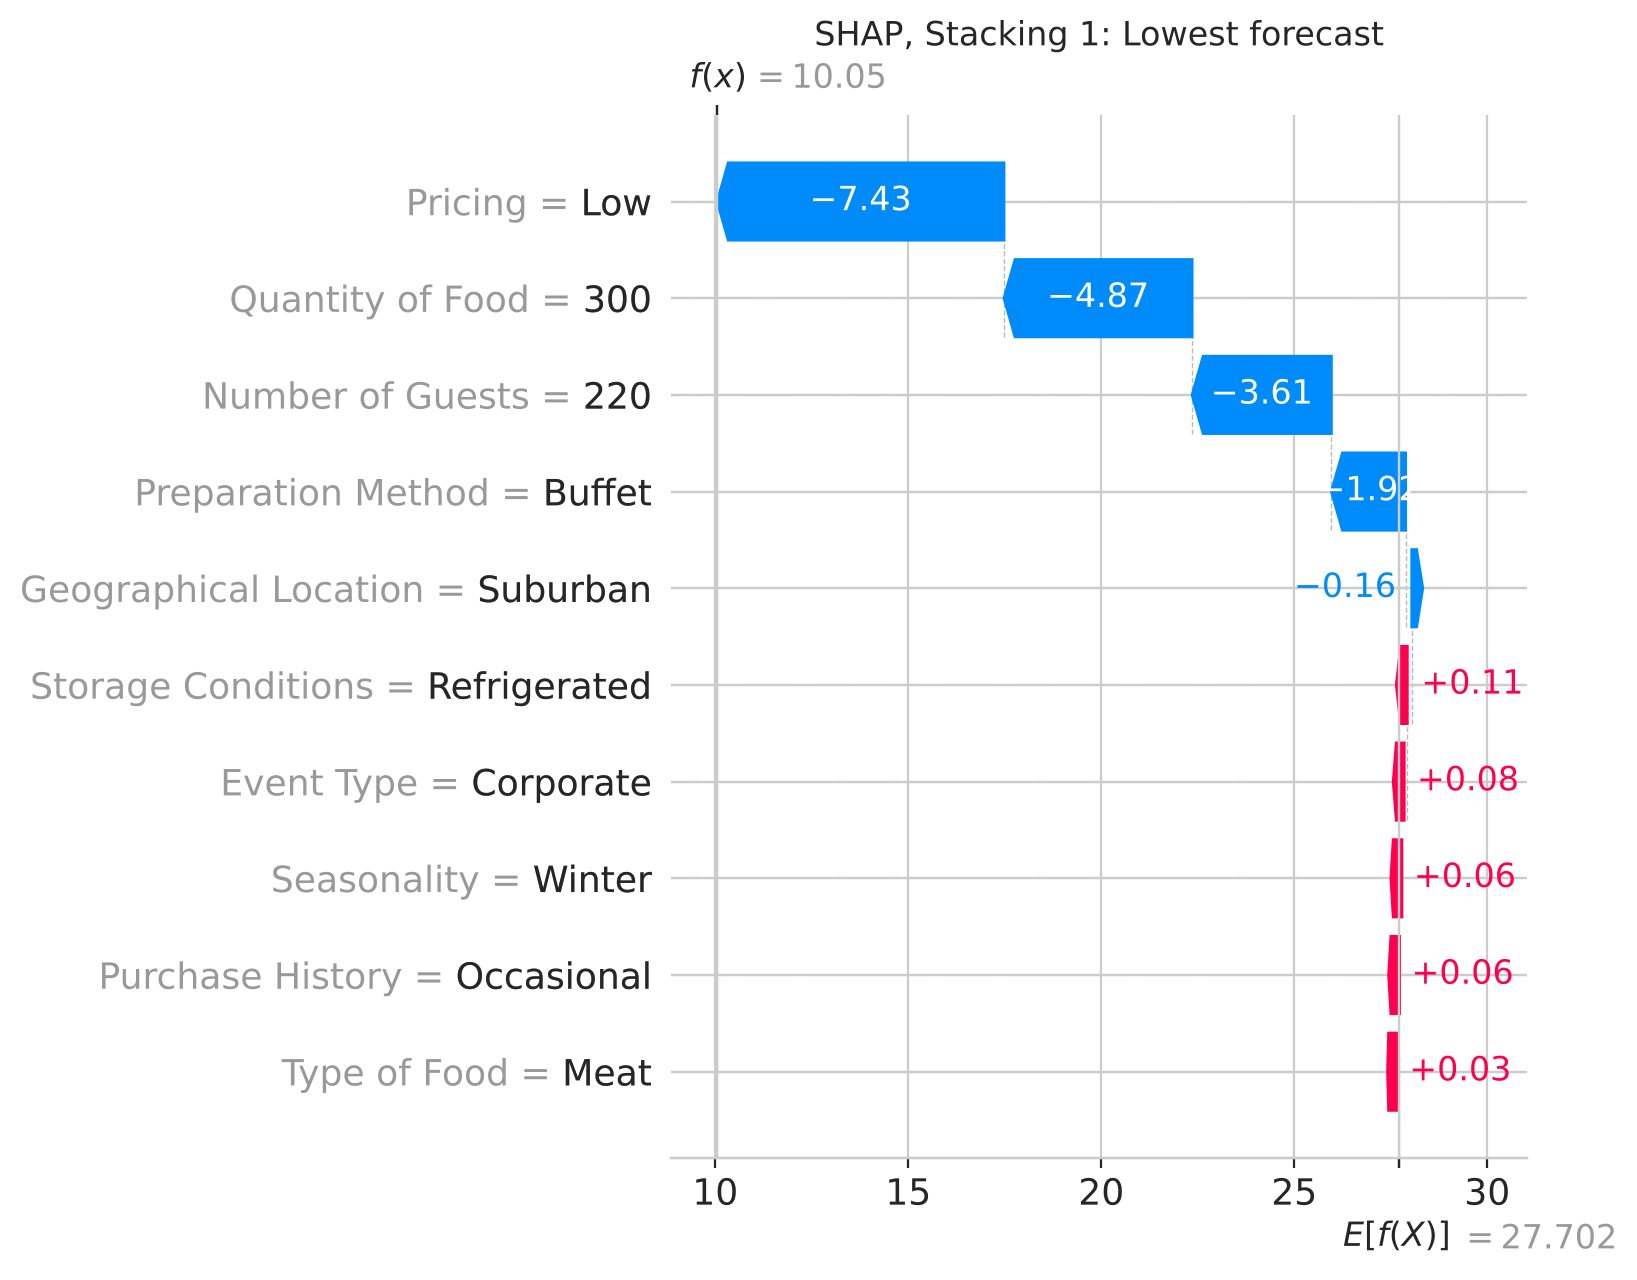

LIME, Stacking 1: Lowest forecast | forecast 10.0


,LIME condition (scaled inputs),Effect
0,Pricing_High <= 0.00,-12.8
1,Quantity of Food <= 0.32,-2.5
2,Number of Guests <= 0.21,-1.7
3,0.00 < Pricing_Low <= 1.00,-1.4
4,Preparation Method_Sit-down Dinner <= 0.00,-1.1
5,Preparation Method_Buffet > 0.00,0.8
6,Geographical Location_Urban <= 0.00,-0.6
7,Geographical Location_Rural <= 0.00,0.4


Top 3 variables, Stacking 1 - SHAP: ['Pricing', 'Quantity of Food', 'Number of Guests'] | LIME: ['Pricing', 'Quantity of Food', 'Number of Guests']



In [20]:
# CHANGED: new cell. SHAP waterfall plots and LIME explanations of two example test rows
s1_ex = preds["Stacking 1"][ex]
examples = {"Highest forecast": int(np.argmax(s1_ex)), "Lowest forecast": int(np.argmin(s1_ex))}   # positions within the explained rows
lime_explainer = LimeTabularExplainer(X_tr, feature_names=list(X.columns), mode="regression", random_state=RANDOM_STATE)

def label(var, row):
    # Variable name with its original value in that row, for the plot labels
    value = df[var].iloc[row] if var in CAT_COLS else X[var].iloc[row]
    return f"{var} = {value}" if var in CAT_COLS else f"{var} = {value:,.0f}"

for title, r in examples.items():
    t = ex[r]                       # position in the test set
    row = df.iloc[idx_te[t]]
    print(f"{title}: {row['Type of Food']}, {row['Event Type']}, {row['Number of Guests']} guests, "
          f"{row['Quantity of Food']} food | actual {y_te[t]:,.0f}")
    for name, res in xai.items():
        # SHAP waterfall with one bar per original variable
        exp = shap.Explanation(values=res["shap"][r], base_values=res["sv"].base_values[r],
                               feature_names=[label(v, idx_te[t]) for v in res["vars"]])
        shap.plots.waterfall(exp, max_display=10, show=False)
        plt.title(f"SHAP, {name}: {title}"); plt.tight_layout(); plt.show()

        # LIME around the same row
        lime_exp = lime_explainer.explain_instance(X_te[t], s1.predict, num_features=8)
        print(f"LIME, {name}: {title} | forecast {preds[name][t]:,.1f}")
        display(pd.DataFrame(lime_exp.as_list(), columns=["LIME condition (scaled inputs)", "Effect"]).round(1))

        # Compare the three most important variables from SHAP and LIME
        shap_top = [str(v) for v in np.array(res["vars"])[np.argsort(-np.abs(res["shap"][r]))]][:3]
        lime_top = []
        for cond, _ in lime_exp.as_list():
            v = next((d for d in res["vars"] if d in cond), cond)
            if v not in lime_top: lime_top.append(v)
        print(f"Top 3 variables, {name} - SHAP: {shap_top} | LIME: {lime_top[:3]}\n")